# 19장 비용·성능 분석

1~18장의 결과 파일을 한 장부에 모은다. 새 실험은 하지 않고 Jev도 부르지 않는다. 답할 질문은 셋이다.

- 같은 성능을 내는 데 각 구성이 무엇을 얼마나 쓰는가(사람 라벨, 사람 비용, 입력 토큰, 시간)?
- 사람 단가와 검수 비율, 문장 길이 가정을 바꾸면 결론이 뒤집히는가?
- 처음 능동 학습을 들이는 팀은 어떤 구성으로 시작해야 하는가?

- 19.1 비용 모델의 구성 요소
- 19.2 라벨 수 대비 성능
- 19.3 API 호출 수와 토큰 사용량
- 19.4 손익분기 분석
- 19.5 데이터셋별 결과 비교
- 19.6 운영 권장 구성

In [1]:
# ── 환경 설정과 상수 ────
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib

SEEDS = [0, 1, 2, 3, 4]
N_INIT, K, BUDGET = 100, 50, 2000
GRID = np.arange(N_INIT, BUDGET + 1, K)
ACCENT, INK, GRAY, GRAY2 = "#E32C24", "#1C1C1A", "#575753", "#8C8A85"
R = "results"

# 00_기획안 4.2절 가정: 사람 라벨 단가(원)와 라벨 하나에 드는 시간(초). 검수는 단가와 시간의 60%
UNIT = {"nsmc": 50, "ynat": 80}
SEC = {"nsmc": 8, "ynat": 12}
RHO = 0.6

def alc(n, m, budget=BUDGET):
    # 라벨 수를 [n0, budget] → [0, 1]로 정규화한 사다리꼴 적분(2장)
    keep = n <= budget
    u, m = (n[keep] - n[0]) / (budget - n[0]), m[keep]
    return np.sum(np.diff(u) * (m[1:] + m[:-1]) / 2)

def label_efficiency(n, m, m_target, budget=BUDGET):
    hit = n[m >= m_target]
    return budget / hit[0] if len(hit) else np.nan

## 19.1 비용 모델의 구성 요소

구성 하나의 총비용을 네 항으로 나눈다. 사람이 붙인 라벨 n_label에 단가 u를 곱한 값, 검수 n_review에 검수 단가 ρu를 곱한 값, Jev 입력 토큰 T_in에 토큰 단가 p를 곱한 값, 그리고 고정비다. 고정비는 초기 라벨 100개와 퓨샷 예시처럼 모든 구성이 똑같이 내는 비용이다. 초기 라벨 100개는 n_label에 이미 들어 있으므로 따로 더하지 않는다.

C = n_label · u + n_review · ρu + p · T_in

사람 시간도 같은 식으로 센다(라벨 하나 NSMC 8초, YNAT 12초, 검수는 60%). 토큰 단가 p는 원화로 바꾸지 않는다. 독자가 자기 단가를 넣어 읽을 수 있게 손익분기 단가 p*를 낸다.

장부의 행은 (장, 데이터, 질의, 오라클)이다. 결과 파일마다 토큰 열의 뜻이 달라 읽는 법을 하나씩 정한다.

| 장 | 토큰 열 | 읽는 법 |
|---|---|---|
| 10·11장 | n_in | 라운드마다 쓴 입력 토큰. 시드마다 더한다(3부 형식) |
| 16·18장 | tok | 누적값. 마지막 행 |
| 17장 | tok_q, tok_o | 질의 판정·오라클 판정의 누적 몫. 마지막 행의 합 |

In [2]:
# ── 장부에 올릴 구성 ────
# (이름, 장, 시나리오, 오라클, 파일 패턴, 전략 열 값, 토큰 읽는 법)
# 파일 패턴의 {d}는 데이터, {s}는 시드다. 전략 열 값이 None이면 파일 하나가 한 구성이다
def ch15_mix(d):
    return "신뢰도_20_·_라벨_평활화" if d == "ynat" else "신뢰도_20"

SPEC = [
    ("Random·사람", "2", "풀", "사람", "ch02_random_{d}.csv", "Random", None),
    ("엔트로피·사람", "3", "풀", "사람", "ch03_{d}.csv", "엔트로피", None),
    ("QBC 배깅5·KL", "4", "풀", "사람", "ch04_{d}.csv", "배깅5·KL", None),
    ("BADGE", "8", "풀", "사람", "ch08_{d}.csv", "BADGE", None),
    ("코어셋", "8", "풀", "사람", "ch08_{d}.csv", "코어셋", None),
    ("규칙 변형·교사", "7", "합성", "교사", "ch07_{d}.csv", "규칙 변형", None),
    ("Jev 불일치·사람(3부)", "10", "풀", "사람", "ch10_parts/{d}_kl150_{s}.csv", None, "n_in"),
    ("엔트로피·Jev 필터", "11", "풀", "사람", "ch11_parts/{d}_filter_k50_{s}.csv", None, "n_in"),
    ("결합 선택기", "11", "풀", "사람", "ch11_parts/{d}_combo_k50_{s}.csv", None, "n_in"),
    ("Random·Jev", "16", "풀", "Jev", "ch16_parts/loop_{d}_Random_Jev_{s}.csv", None, "tok"),
    ("Random·혼합", "16", "풀", "혼합", "ch16_parts/loop_{d}_Random_혼합_{s}.csv", None, "tok"),
    ("엔트로피·Jev", "17", "풀", "Jev", "ch17_parts/loop_{d}_엔트로피-Jev_{s}.csv", None, "qo"),
    ("엔트로피·혼합", "17", "풀", "혼합", "ch17_parts/loop_{d}_엔트로피-혼합_{s}.csv", None, "qo"),
    ("Jev 불일치·사람", "17", "풀", "사람", "ch17_parts/loop_{d}_Jev_불일치-사람_{s}.csv", None, "qo"),
    ("Jev 불일치·Jev", "17", "풀", "Jev", "ch17_parts/loop_{d}_Jev_불일치-Jev_{s}.csv", None, "qo"),
    ("Jev 불일치·혼합", "17", "풀", "혼합", "ch17_parts/loop_{d}_Jev_불일치-혼합_{s}.csv", None, "qo"),
    ("VU", "18", "스트림", "사람", "ch18_parts/stream_{d}_VU_{s}.csv", None, "tok"),
    ("VU·Jev", "18", "스트림", "Jev", "ch18_parts/stream_{d}_VU·Jev_{s}.csv", None, "tok"),
    ("Jev 불일치 스트림", "18", "스트림", "Jev", "ch18_parts/stream_{d}_Jev_불일치_스트림_{s}.csv", None, "tok"),
    ("Jev 불일치 스트림·혼합", "18", "스트림", "혼합", "ch18_parts/stream_{d}_Jev_불일치_스트림·혼합_{s}.csv", None, "tok"),
    ("판정 기반 합성", "18", "합성", "Jev", "ch18_parts/synth_{d}_{s}.csv", None, "tok"),
]

def read_runs(d, pattern, strategy):
    if strategy:
        df = pd.read_csv(f"{R}/{pattern.format(d=d)}")
        return [g for _, g in df[df.strategy == strategy].groupby("seed")]
    return [pd.read_csv(f"{R}/{pattern.format(d=d, s=s)}") for s in SEEDS]

def tokens(g, how):
    return {None: lambda: 0.0, "n_in": lambda: g.n_in.sum(), "tok": lambda: g.tok.iloc[-1],
            "qo": lambda: g.tok_q.iloc[-1] + g.tok_o.iloc[-1]}[how]()

def run_row(d, name, ch, scen, oracle, g, how):
    g = g.sort_values("n_labeled")
    f1 = np.interp(GRID, g.n_labeled.values, g.f1.values)        # 스트림은 라벨 수가 고르지 않아 격자에 맞춘다
    n_lab = g.n_labeled.max()
    n_hum = n_lab if oracle == "사람" else N_INIT
    rev = g.reviews.iloc[-1] if "reviews" in g else 0
    return dict(data=d, 구성=name, 장=ch, 시나리오=scen, 오라클=oracle, ALC=alc(GRID, f1), final=f1[-1],
                n_label=n_hum, n_review=rev, tok=tokens(g, how),
                noise=g.noise.iloc[-1] if "noise" in g else (0.0 if oracle == "사람" else np.nan), curve=f1)

runs = pd.DataFrame([run_row(d, *sp[:4], g, sp[6]) for d in ("nsmc", "ynat") for sp in SPEC
                     for g in read_runs(d, sp[4], sp[5])])
print(runs.groupby(["data", "구성"], sort=False).size().unstack(0).T.to_string())

구성    Random·사람  엔트로피·사람  QBC 배깅5·KL  BADGE  코어셋  규칙 변형·교사  Jev 불일치·사람(3부)  엔트로피·Jev 필터  결합 선택기  Random·Jev  Random·혼합  엔트로피·Jev  엔트로피·혼합  Jev 불일치·사람  Jev 불일치·Jev  Jev 불일치·혼합  VU  VU·Jev  Jev 불일치 스트림  Jev 불일치 스트림·혼합  판정 기반 합성
data                                                                                                                                                                                                                             
nsmc          5        5           5      5    5         5               5            5       5           5          5         5        5           5            5           5   5       5            5               5         5
ynat          5        5           5      5    5         5               5            5       5           5          5         5        5           5            5           5   5       5            5               5         5


구성마다 시드 다섯 개가 다 읽혔는지 위 표로 확인한다. 이제 시드 평균으로 장부를 만든다. 비용은 19.1절 식의 사람 항이고, LE는 Random·사람의 라벨 2,000개 F1에 처음 닿는 라벨 수로 예산을 나눈 값이다(1장).

In [3]:
# ── 장부 (표 19.1) ────
def ledger(runs):
    rows = []
    for (d, name), g in runs.groupby(["data", "구성"], sort=False):
        curve = np.mean(np.stack(g.curve.values), axis=0)
        first = g.iloc[0]
        rows.append(dict(data=d, 구성=name, 장=first.장, 시나리오=first.시나리오, 오라클=first.오라클,
                         ALC=g.ALC.mean(), final=curve[-1], curve=curve, n_label=g.n_label.mean(),
                         n_review=g.n_review.mean(), tok=g.tok.mean(), noise=g.noise.mean()))
    L = pd.DataFrame(rows)
    L["cost_h"] = L.n_label * L.data.map(UNIT) + L.n_review * RHO * L.data.map(UNIT)
    L["hours_h"] = (L.n_label + L.n_review * RHO) * L.data.map(SEC) / 3600
    ref = L[L.구성 == "Random·사람"].set_index("data").final
    L["LE"] = [label_efficiency(GRID, c, ref[d]) for d, c in zip(L.data, L.curve)]
    base = L[L.구성 == "엔트로피·사람"].set_index("data").ALC
    L["ALC_비"] = L.ALC / L.data.map(base)
    return L

L = ledger(runs)
COLS = ["장", "시나리오", "구성", "ALC", "ALC_비", "final", "LE", "noise", "n_label", "n_review", "cost_h", "hours_h", "tok"]
for d in ("nsmc", "ynat"):
    print(f"\n{d} 장부 (ALC_비 = 엔트로피·사람 대비, noise = 학습 라벨 오류율, cost_h = 사람 비용(원), hours_h = 사람 시간, tok = Jev 입력 토큰)")
    print(L[L.data == d][COLS].round({"ALC": 4, "ALC_비": 3, "final": 4, "LE": 2, "noise": 3, "n_label": 0,
                                       "n_review": 0, "cost_h": 0, "hours_h": 2, "tok": 0}).to_string(index=False))


nsmc 장부 (ALC_비 = 엔트로피·사람 대비, noise = 학습 라벨 오류율, cost_h = 사람 비용(원), hours_h = 사람 시간, tok = Jev 입력 토큰)
 장 시나리오             구성    ALC  ALC_비  final   LE  noise  n_label  n_review   cost_h  hours_h       tok
 2    풀      Random·사람 0.7426  0.993 0.7802 1.00  0.000   2000.0       0.0 100000.0     4.44       0.0
 3    풀        엔트로피·사람 0.7479  1.000 0.7860 1.21  0.000   2000.0       0.0 100000.0     4.44       0.0
 4    풀     QBC 배깅5·KL 0.7306  0.977 0.7708  NaN  0.000   2000.0       0.0 100000.0     4.44       0.0
 8    풀          BADGE 0.7401  0.990 0.7830 1.08  0.000   2000.0       0.0 100000.0     4.44       0.0
 8    풀            코어셋 0.6998  0.936 0.7731  NaN  0.000   2000.0       0.0 100000.0     4.44       0.0
 7   합성       규칙 변형·교사 0.7559  1.011 0.7948 1.48    NaN    100.0       0.0   5000.0     0.22       0.0
10    풀 Jev 불일치·사람(3부) 0.7694  1.029 0.8057 2.22  0.000   2000.0       0.0 100000.0     4.44 1674582.0
11    풀    엔트로피·Jev 필터 0.7501  1.003 0.7880 1.25  0.000   2000.0       0.0

교사 칸(7장)은 풀 정답 전부로 학습한 교사가 라벨을 붙이므로 현실에서는 만들 수 없는 오라클이다. 장부에는 참고로 두고 비교에서는 뺀다. 예산이 라벨 1,000개인 5장(EER)과 9장(사전학습 모델 실험)도 같은 축에 놓을 수 없어 따로 본다.

In [4]:
# ── 예산 1,000개 장 (같은 축 비교에서 제외) ────
b1000 = []
for d in ("nsmc", "ynat"):
    for f, names in [(f"ch05_eer_{d}.csv", ["Random", "엔트로피", "EER"]), (f"ch09_{d}.csv", ["Random", "엔트로피", "BALD", "BADGE"])]:
        df = pd.read_csv(f"{R}/{f}")
        for nm in names:
            g = df[df.strategy == nm]
            b1000.append(dict(data=d, 장=f[2:4], 구성=nm, 시드=g.seed.nunique(),
                              ALC_1000=np.mean([alc(x.n_labeled.values, x.f1.values, 1000) for _, x in g.groupby("seed")]),
                              final_1000=g[g.n_labeled == 1000].f1.mean()))
print(pd.DataFrame(b1000).round(4).to_string(index=False))

data  장     구성  시드  ALC_1000  final_1000
nsmc 05 Random   3    0.7109      0.7535
nsmc 05   엔트로피   3    0.7188      0.7581
nsmc 05    EER   3    0.7245      0.7629
nsmc 09 Random   5    0.8322      0.8475
nsmc 09   엔트로피   5    0.8048      0.8559
nsmc 09   BALD   5    0.7978      0.7480
nsmc 09  BADGE   5    0.8011      0.7491
ynat 05 Random   3    0.4552      0.5626
ynat 05   엔트로피   3    0.5292      0.6515
ynat 05    EER   3    0.5228      0.6427
ynat 09 Random   5    0.7763      0.8280
ynat 09   엔트로피   5    0.7931      0.8476
ynat 09   BALD   5    0.7703      0.8405
ynat 09  BADGE   5    0.7966      0.8399


## 19.2 라벨 수 대비 성능

사람 비용과 ALC를 두 축으로 놓는다. 같은 사람 비용에서 ALC가 가장 높은 구성들을 이은 선이 효율 경계다. 토큰 비용은 여기서 빼고 19.4절에서 더한다.

nsmc 효율 경계: Jev 불일치·Jev
ynat 효율 경계: Jev 불일치 스트림 → 엔트로피·혼합 → 엔트로피·사람


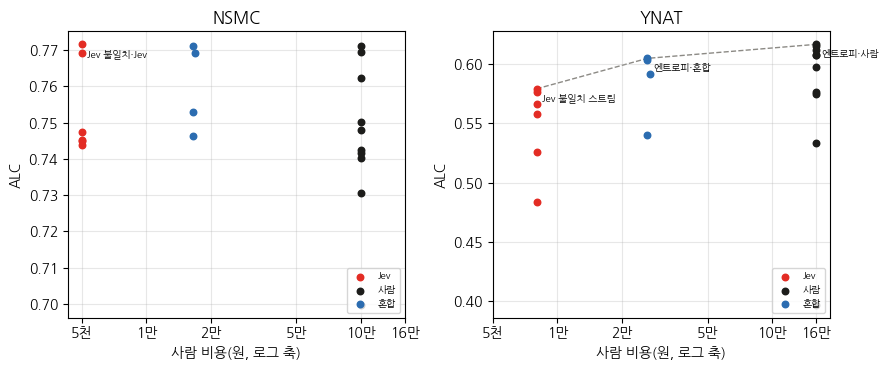

In [5]:
# ── 효율 경계 (그림 19.2) ────
def frontier(df):
    df = df.sort_values(["cost_h", "ALC"], ascending=[True, False])
    best, keep = -1, []
    for _, r in df.iterrows():
        if r.ALC > best:
            keep.append(r.구성)
            best = r.ALC
    return keep

V = L[L.오라클 != "교사"]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
COL = {"사람": INK, "Jev": ACCENT, "혼합": "#2B6CB0"}
for ax, d in zip(axes, ("nsmc", "ynat")):
    g = V[V.data == d]
    fr = g.set_index("구성").loc[frontier(g)]
    ax.plot(fr.cost_h, fr.ALC, color=GRAY2, lw=1, ls="--", zorder=1)
    for o, h in g.groupby("오라클"):
        ax.scatter(h.cost_h, h.ALC, s=22, color=COL[o], label=o, zorder=2)
    for name, r in fr.iterrows():
        ax.annotate(name, (r.cost_h, r.ALC), fontsize=7, xytext=(4, -9), textcoords="offset points")
    ax.set_xscale("log")
    ax.set_xticks([5000, 10000, 20000, 50000, 100000, 160000], ["5천", "1만", "2만", "5만", "10만", "16만"])
    ax.minorticks_off()
    ax.set(title=d.upper(), xlabel="사람 비용(원, 로그 축)", ylabel="ALC")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7, loc="lower right")
    print(d, "효율 경계:", " → ".join(frontier(g)))
fig.tight_layout()
fig.savefig("out/ch19_frontier.png", dpi=200)

## 19.3 API 호출 수와 토큰 사용량

3부(10·11장)는 질문 정의를 문장마다 되풀이하는 3부 형식으로 판정했다. 13장에서 같은 2,000문장을 형식마다 판정해 문장당 입력 토큰을 쟀으므로, 그 비율로 3부 칸의 토큰을 슬림 형식(13장 최종 설정)으로 다시 친다.

In [6]:
# ── 3부 형식 → 슬림 형식 환산 ────
SLIM = {"nsmc": "균형8_s0", "ynat": "균형7_s0"}           # 13장 최종 설정(스키마 + 클래스 균형 예시)
ratio = {}
for d in ("nsmc", "ynat"):
    old = pd.read_csv(f"{R}/ch13_parts/static_{d}_3부 형식.csv").n_in.mean()
    new = pd.read_csv(f"{R}/ch13_parts/static_{d}_{SLIM[d]}.csv").n_in.mean()
    ratio[d] = new / old
    print(f"{d}: 문장당 입력 토큰 3부 형식 {old:.1f} → 슬림 {new:.1f} (비율 {ratio[d]:.3f})")

L["tok_slim"] = np.where(L.장.isin(["10", "11"]), L.tok * L.data.map(ratio), L.tok)

nsmc: 문장당 입력 토큰 3부 형식 121.0 → 슬림 81.7 (비율 0.675)


ynat: 문장당 입력 토큰 3부 형식 205.9 → 슬림 112.2 (비율 0.545)


Jev를 쓰는 구성은 사람 라벨을 아끼는 대가로 토큰을 쓴다. 사람 라벨 하나를 아끼는 데 드는 토큰 τ_save를 구한다. n*는 그 구성이 쓴 사람 라벨(검수는 ρ만큼 센다), B는 예산 2,000이다.

τ_save = T_in / (B − n*)

In [7]:
# ── 라벨 하나를 아끼는 토큰 ────
J = L[L.오라클.isin(["Jev", "혼합"])].copy()
J["n_star"] = J.n_label + J.n_review * RHO
J["tau_save"] = J.tok_slim / (BUDGET - J.n_star)
for d in ("nsmc", "ynat"):
    print(f"\n{d} (tok_slim = 슬림 형식 기준 입력 토큰, n_star = 사람 라벨 환산, tau_save = 사람 라벨 하나를 아끼는 토큰)")
    print(J[J.data == d][["구성", "ALC", "tok_slim", "n_star", "tau_save"]].round({"ALC": 4, "tok_slim": 0, "n_star": 0, "tau_save": 1}).to_string(index=False))
H = L[L.장.isin(["10", "11"])][["data", "구성", "tok", "tok_slim"]]
print("\n3부 질의 전략의 토큰(사람 오라클이라 라벨을 아끼지 않는다)")
print(H.round(0).to_string(index=False))


nsmc (tok_slim = 슬림 형식 기준 입력 토큰, n_star = 사람 라벨 환산, tau_save = 사람 라벨 하나를 아끼는 토큰)
            구성    ALC  tok_slim  n_star  tau_save
    Random·Jev 0.7452  155285.0   100.0      81.7
     Random·혼합 0.7463  155285.0   328.0      92.9
      엔트로피·Jev 0.7450  155163.0   100.0      81.7
       엔트로피·혼합 0.7528  176476.0   328.0     105.5
   Jev 불일치·Jev 0.7716  600728.0   100.0     316.2
    Jev 불일치·혼합 0.7710  606283.0   328.0     362.6
        VU·Jev 0.7474  195640.0   100.0     103.0
   Jev 불일치 스트림 0.7691  551046.0   100.0     290.0
Jev 불일치 스트림·혼합 0.7693  571973.0   336.0     343.8
      판정 기반 합성 0.7439 1096281.0   100.0     577.0

ynat (tok_slim = 슬림 형식 기준 입력 토큰, n_star = 사람 라벨 환산, tau_save = 사람 라벨 하나를 아끼는 토큰)
            구성    ALC  tok_slim  n_star  tau_save
    Random·Jev 0.4840  212907.0   100.0     112.1
     Random·혼합 0.5398  212907.0   328.0     127.3
      엔트로피·Jev 0.5574  212134.0   100.0     111.6
       엔트로피·혼합 0.6046  283218.0   328.0     169.4
   Jev 불일치·Jev 0.5761  823344.0   10

## 19.4 손익분기 분석

목표 성능을 정하고 그 목표에 닿는 구성끼리 총비용을 비교한다. 목표는 엔트로피·사람 ALC의 98%와 99%, 그리고 라벨 2,000개 F1이 엔트로피·사람 이상인 것 세 가지다. 사람 오라클 구성은 비용이 모두 같으므로(라벨 2,000개) 기준을 엔트로피·사람으로 둔다. Jev 구성 A가 기준보다 싼 조건은 다음과 같다.

p < p* = (C_H^기준 − C_H^A) / (T_in^A − T_in^기준)

기준의 토큰은 0이다. p*는 원/1,000토큰으로 적는다. 토큰을 쓰는 사람 오라클 구성(10·11장, 17장 Jev 불일치·사람)은 사람 비용이 기준과 같아 토큰만큼 더 비싸므로 목표를 넘어도 p* 비교에서 빠진다.

In [8]:
# ── 목표별 손익분기 단가 ────
def targets(L, d):
    b = L[(L.data == d) & (L.구성 == "엔트로피·사람")].iloc[0]
    return {"ALC 98%": lambda r: r.ALC >= 0.98 * b.ALC, "ALC 99%": lambda r: r.ALC >= 0.99 * b.ALC,
            "F1 이상": lambda r: r.final >= b.final}

BE = []
for d in ("nsmc", "ynat"):
    base_cost = L[(L.data == d) & (L.구성 == "엔트로피·사람")].cost_h.iloc[0]
    for tname, ok in targets(L, d).items():
        for _, r in L[(L.data == d) & L.오라클.isin(["Jev", "혼합"])].iterrows():
            if ok(r):
                BE.append(dict(data=d, 목표=tname, 구성=r.구성, ALC=r.ALC, final=r.final, cost_h=r.cost_h,
                               tok_slim=r.tok_slim, p_star=(base_cost - r.cost_h) / r.tok_slim * 1000))
BE = pd.DataFrame(BE)
print("p_star = 이 구성이 엔트로피·사람보다 싸지는 토큰 단가 상한(원/1,000토큰)")
print(BE.round({"ALC": 4, "final": 4, "cost_h": 0, "tok_slim": 0, "p_star": 1}).to_string(index=False))

p_star = 이 구성이 엔트로피·사람보다 싸지는 토큰 단가 상한(원/1,000토큰)
data      목표             구성    ALC  final  cost_h  tok_slim  p_star
nsmc ALC 98%     Random·Jev 0.7452 0.7788  5000.0  155285.0   611.8
nsmc ALC 98%      Random·혼합 0.7463 0.7821 16400.0  155285.0   538.4
nsmc ALC 98%       엔트로피·Jev 0.7450 0.7825  5000.0  155163.0   612.3
nsmc ALC 98%        엔트로피·혼합 0.7528 0.7902 16400.0  176476.0   473.7
nsmc ALC 98%    Jev 불일치·Jev 0.7716 0.8069  5000.0  600728.0   158.1
nsmc ALC 98%     Jev 불일치·혼합 0.7710 0.8062 16400.0  606283.0   137.9
nsmc ALC 98%         VU·Jev 0.7474 0.7864  5000.0  195640.0   485.6
nsmc ALC 98%    Jev 불일치 스트림 0.7691 0.8037  5000.0  551046.0   172.4
nsmc ALC 98% Jev 불일치 스트림·혼합 0.7693 0.8058 16814.0  571973.0   145.4
nsmc ALC 98%       판정 기반 합성 0.7439 0.7840  5000.0 1096281.0    86.7
nsmc ALC 99%     Random·Jev 0.7452 0.7788  5000.0  155285.0   611.8
nsmc ALC 99%      Random·혼합 0.7463 0.7821 16400.0  155285.0   538.4
nsmc ALC 99%       엔트로피·Jev 0.7450 0.7825  5000.0  155163.0   612.3

가정을 바꿔 결론이 뒤집히는지 본다. 기준점(사람 단가 ×1, 검수 비율 ρ = 0.6, 문장당 토큰 ×1)에서 한 번에 하나씩 바꾼다. 문장당 토큰 ×2는 문서가 두 배 길어진 경우다. 시나리오마다 토큰 단가 p를 바꿔 가며 목표에 닿는 구성 가운데 총비용이 가장 낮은 구성을 찾고, 그 구성이 바뀌는 경계 p를 적는다. 목표는 ALC 98%와, 엔트로피·사람과 같거나 높은 ALC(100%) 두 가지다. 사람 오라클 구성 가운데서는 엔트로피·사람이 후보다. 경계는 바뀌기 직전 구성과 직후 구성의 총비용이 같아지는 p로 정확히 계산한다.


nsmc — ALC 98% 목표에서 토큰 단가(원/1,000토큰) 구간별 가장 싼 구성


  기준      : 엔트로피·Jev | 612.3부터 엔트로피·사람
  단가 ×0.5 : 엔트로피·Jev | 306.1부터 엔트로피·사람
  단가 ×2   : 엔트로피·Jev | 1224.5부터 엔트로피·사람
  검수 0.4  : 엔트로피·Jev | 612.3부터 엔트로피·사람
  검수 0.8  : 엔트로피·Jev | 612.3부터 엔트로피·사람
  토큰 ×0.5 : 엔트로피·Jev | 1224.5부터 엔트로피·사람
  토큰 ×2   : 엔트로피·Jev | 306.1부터 엔트로피·사람

nsmc — ALC 100% 목표에서 토큰 단가(원/1,000토큰) 구간별 가장 싼 구성
  기준      : Jev 불일치 스트림 | 30.4부터 엔트로피·혼합 | 473.7부터 엔트로피·사람
  단가 ×0.5 : Jev 불일치 스트림 | 15.2부터 엔트로피·혼합 | 236.9부터 엔트로피·사람
  단가 ×2   : Jev 불일치 스트림 | 60.9부터 엔트로피·혼합 | 947.4부터 엔트로피·사람
  검수 0.4  : Jev 불일치 스트림 | 20.3부터 엔트로피·혼합 | 495.3부터 엔트로피·사람
  검수 0.8  : Jev 불일치 스트림 | 40.6부터 엔트로피·혼합 | 452.2부터 엔트로피·사람
  토큰 ×0.5 : Jev 불일치 스트림 | 60.9부터 엔트로피·혼합 | 947.4부터 엔트로피·사람
  토큰 ×2   : Jev 불일치 스트림 | 15.2부터 엔트로피·혼합 | 236.9부터 엔트로피·사람

ynat — ALC 98% 목표에서 토큰 단가(원/1,000토큰) 구간별 가장 싼 구성
  기준      : 엔트로피·혼합 | 472.3부터 엔트로피·사람
  단가 ×0.5 : 엔트로피·혼합 | 236.1부터 엔트로피·사람
  단가 ×2   : 엔트로피·혼합 | 944.6부터 엔트로피·사람
  검수 0.4  : 엔트로피·혼합 | 493.8부터 엔트로피·사람
  검수 0.8  : 엔트로피·혼합 | 450.8부터 엔트로피·사람
  토큰 ×0.5 : 엔트로피·혼합 |

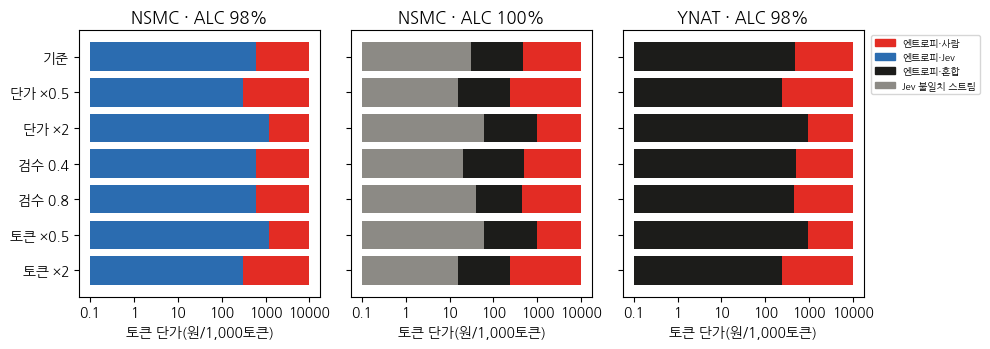

In [9]:
# ── 민감도: 가장 싼 구성이 바뀌는 경계 (그림 19.3) ────
SCEN = [("기준", 1, RHO, 1), ("단가 ×0.5", 0.5, RHO, 1), ("단가 ×2", 2, RHO, 1), ("검수 0.4", 1, 0.4, 1),
        ("검수 0.8", 1, 0.8, 1), ("토큰 ×0.5", 1, RHO, 0.5), ("토큰 ×2", 1, RHO, 2)]
P = np.logspace(-1, 4, 1001)                                # 원/1,000토큰

def cheapest(d, goal, um, rho, tm):
    b = L[(L.data == d) & (L.구성 == "엔트로피·사람")].iloc[0]
    C = L[(L.data == d) & (L.ALC >= goal * b.ALC) & (L.오라클 != "교사") & ((L.오라클 != "사람") | (L.구성 == "엔트로피·사람"))]
    fix = um * (C.n_label.values + rho * C.n_review.values) * UNIT[d]
    var = tm * C.tok_slim.values / 1000
    w = (fix[:, None] + var[:, None] * P[None, :]).argmin(0)
    cut = np.flatnonzero(w[1:] != w[:-1])
    edges = [(fix[w[i + 1]] - fix[w[i]]) / (var[w[i]] - var[w[i + 1]]) for i in cut]   # 두 구성의 총비용이 같아지는 p
    return C.구성.values[w], C.구성.values[w[cut + 1]], edges

GOALS = [("nsmc", 0.98), ("nsmc", 1.0), ("ynat", 0.98)]
SENS = {}
for d, goal in GOALS:
    print(f"\n{d} — ALC {goal:.0%} 목표에서 토큰 단가(원/1,000토큰) 구간별 가장 싼 구성")
    for sc, um, rho, tm in SCEN:
        w, nxt, edges = cheapest(d, goal, um, rho, tm)
        SENS[(d, goal, sc)] = w
        print(f"  {sc:8s}: " + " | ".join([w[0]] + [f"{e:.1f}부터 {n}" for e, n in zip(edges, nxt)]))
print("\nYNAT에서 ALC 100%에 닿는 Jev 구성:", list(L[(L.data == "ynat") & L.오라클.isin(["Jev", "혼합"]) & (L.ALC_비 >= 1)].구성))

names = sorted({n for w in SENS.values() for n in w}, key=lambda n: list(L.구성.unique()).index(n))
PAL = dict(zip(names, [ACCENT, "#2B6CB0", INK, GRAY2, "#9C6B30", "#6B8E23", GRAY]))
fig, axes = plt.subplots(1, 3, figsize=(10, 3.6), sharey=True)
TICKS = [0.1, 1, 10, 100, 1000, 10000]
for ax, (d, goal) in zip(axes, GOALS):
    for y, (sc, *_ ) in enumerate(SCEN):
        w = SENS[(d, goal, sc)]
        for i in range(len(P) - 1):
            ax.fill_between([P[i], P[i + 1]], y - 0.4, y + 0.4, color=PAL[w[i]], lw=0)
    ax.set_xscale("log")
    ax.set_xticks(TICKS, [f"{t:g}" for t in TICKS])
    ax.minorticks_off()
    ax.set(title=f"{d.upper()} · ALC {goal:.0%}", xlabel="토큰 단가(원/1,000토큰)", yticks=range(len(SCEN)))
    ax.set_yticklabels([s[0] for s in SCEN])
axes[0].invert_yaxis()
axes[-1].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=PAL[n]) for n in names], labels=names, fontsize=7,
               loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout()
fig.savefig("out/ch19_sensitivity.png", dpi=200)

## 19.5 데이터셋별 결과 비교

두 데이터에서 결론이 갈리는 지점을 Jev 라벨 정확도와 클래스 수로 정리한다. Jev 오라클 칸의 학습 라벨 오류율(noise)과 엔트로피·사람 대비 ALC를 나란히 놓는다.

In [10]:
# ── 데이터별 비교 ────
cmp = L[L.오라클.isin(["Jev", "혼합"])].pivot_table(index="구성", columns="data", values=["ALC_비", "noise"], sort=False)
print(cmp.round(3).to_string())
for d in ("nsmc", "ynat"):
    g = L[(L.data == d) & L.오라클.isin(["Jev", "혼합"])]
    print(f"{d}: noise와 ALC_비의 상관 {np.corrcoef(g.noise, g.ALC_비)[0, 1]:.3f}  (구성 {len(g)}개)")

                ALC_비         noise       
data             nsmc   ynat   nsmc   ynat
구성                                        
Random·Jev      0.996  0.785  0.095  0.162
Random·혼합       0.998  0.876  0.034  0.082
엔트로피·Jev        0.996  0.904  0.137  0.260
엔트로피·혼합         1.007  0.981  0.059  0.159
Jev 불일치·Jev     1.032  0.935  0.039  0.232
Jev 불일치·혼합      1.031  0.978  0.025  0.144
VU·Jev          0.999  0.852  0.116  0.231
Jev 불일치 스트림     1.028  0.939  0.042  0.196
Jev 불일치 스트림·혼합  1.029  0.960  0.024  0.122
판정 기반 합성        0.995  0.919  0.145  0.260
nsmc: noise와 ALC_비의 상관 -0.771  (구성 10개)
ynat: noise와 ALC_비의 상관 -0.068  (구성 10개)
